# PSIONIC Tutorial part 1

**Date:** 2026-07-30

**Author:** Jiahui Hou (jih325@pitt.edu)

**Data required:** scATAC-seq + scRNA-seq

The PSIONIC tutorial has two parts. In the first part, I demonstrate the code for tuning the PSIONIC model using cross-validation and selecting the best-performing model hyperparameters. In the second part, I demonstrate how to run the model on the full dataset using those best hyperparameters, then interpret the model output and perform differential TF activity analysis.

## Main steps of part 1

1. **Step 1.** Create cell-type pseudobulk from scATAC-seq
2. **Step 2.** Create TF–gene matrix (**D**) for each cell type using snATAC-seq pseudobulk
3. **Step 3.** Create cell-type × sample pseudobulk from scRNA-seq (**Y**)
4. **Step 4.** Run PSIONIC cross-validation training
5. **Step 5.** Examine the performance of PSIONIC model

## Step 1 — Create cell-type pseudobulk from scATAC-seq

We start from a QC'd, processed peak-count matrix (from snATAC-seq or scATAC-seq)
that already has **cell-type annotations**. In this step we aggregate the
single-cell counts within each cell type to produce a pseudobulk profile
per cell type.

We save the pseudobulk data in the **10x Genomics MEX / MTX sparse-matrix
format** — a folder containing three files:

| File | Contents |
|------|----------|
| `matrix.mtx.gz` | Aggregated counts, shape **peaks × cell types** |
| `barcodes.tsv.gz` | Cell-type names (one per column of the matrix data) |
| `features.tsv.gz` | Peak metadata: `gene_ids`, `gene_symbols`, `feature_types` |

> **Note on `features.tsv.gz`.** The format follows the 10x convention, but our
> features are ATAC peaks, not genes. The first two columns are built from the
> peak coordinates as `chr_start_end` (e.g. `chr1_817093_817593`). Please make sure the chromosomes in your data are in the **chx format**.  
> We use the peak coordinate string for both `gene_ids` and `gene_symbols`.
> `feature_types` can be coded as `"Gene Expression"` (kept for 10x loader compatibility, even though these are ATAC peaks).

## Step 2 — Create TF–gene matrix (D) for each cell type using scATAC-seq pseudobulk

For the sake of memory and run-time, here we provide a **toy scATAC-seq pseudobulk dataset** to demonstrate the code, and we identify target gene matrices for **50 TFs**.

The toy dataset can be found in the **`toy_pseudobulk_count_matrix`** folder. The toy data were created from peaks on Chromosome 1 and include only two cell types (excitatory neuron and oligodendrocyte).

In this step we:
1. Create target-gene potential scores for each selected TF across all cell types using `create_TF_target_matrix()`.
2. Combine them into a **TF × gene matrix (D)** for each cell type using `combine_tf_results()`.

In [1]:
import sys, os
import pandas as pd
import psionic
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# Optional: write PSIONIC log messages to a file
psionic.set_log_file("tf_imputation_full.log")

In [2]:
# Load selcted 50 TFs
tf_df = pd.read_csv("./data/selected_50_TFs.csv")
tf_names = sorted(tf_df["TF"].unique()) 
print(f"Number of unique TFs in file: {len(tf_names)}")

Number of unique TFs in file: 50


In [3]:
results = psionic.create_TF_target_matrix(
    input_matrix_path="./data/toy_pseudobulk_count_matrix",
    factors=tf_names,
    species="human", 
    n_cores=1,
    corr_csv_template=None,
)

celltype_results = psionic.combine_tf_results(
    results,
    out_dir="./SCRIP_out", # output folder for TF × gene matrix (D), one for each cell type
    save=True
)


## Step 3. Create cell-type × sample pseudobulk from scRNA-seq (Y)

We provide a **toy scRNA-seq pseudobulk dataset** (toy_Y.h5ad) in which gene expression has been aggregated for each cell-type × sample combination. Below are instructions for generating pseudobulks from your own data.

To account for the imbalanced number of cells across cell types, we construct **downsampled** pseudobulks by drawing a fixed number of cells for each pseudobulk. For reference, the function used to create the pseudobulks is shown below.

In [4]:
import numpy as np              
import scipy.sparse as sp       
import pandas as pd             
import anndata as ad            

def make_pseudobulks(
    adata,
    pb_size, # specify how many cells in each pseudobulk
    subject_col="projid", # use your own sample ID column
    celltype_col="cell_type", # use your own cell type column
    random_state=0
):
    rng = np.random.default_rng(random_state)
    
    pb_X = []
    pb_obs = []
    groups = adata.obs.groupby(
        [subject_col, celltype_col],
        observed=True
    ).indices
    
    for (subj, ct), idx in groups.items():
        
        n_cells = len(idx)
        if n_cells < pb_size:
            continue
            
        idx = np.array(idx)
        rng.shuffle(idx)
        chunks = [
            idx[i : i + pb_size]
            for i in range(0, len(idx), pb_size)
            if len(idx[i : i + pb_size]) >= pb_size
        ]
        
        for rep_id, cell_idx in enumerate(chunks, start=1):
            X = adata.X[cell_idx]
            if sp.issparse(X):
                X_sum = sp.csr_matrix(X.sum(axis=0))
            else:
                X_sum = sp.csr_matrix(X.sum(axis=0, keepdims=True))
                
            pb_X.append(X_sum)
            
            pseudo_id = f"{subj}_{ct}_rep{rep_id}"
            pathology = adata.obs.iloc[cell_idx[0]]["diagnosis"] # modify this for your diagnosis column name

            pb_obs.append({
                "subject": subj,
                "cell_type": ct,
                "replicate": rep_id,
                "n_cells": len(cell_idx),
                "pseudo_id": pseudo_id,
                "Pathology": pathology
            })
            
    if len(pb_X) == 0:
        raise ValueError(
            f"No pseudobulks were generated with pb_size={pb_size}. "
            "Check cell counts."
        )
        
    pb_X = sp.vstack(pb_X, format="csr")
    pb_obs = pd.DataFrame(pb_obs)
    # 🔑 use pseudo_id as obs_names
    pb_obs.index = pb_obs["pseudo_id"]
    pb_adata = ad.AnnData(
        X=pb_X,
        obs=pb_obs,
        var=adata.var.copy(),
    )
    
    return pb_adata

# Example function call:
#pb_adata = make_pseudobulks(
#    adata,
#    pb_size = 100,
#    subject_col="subject",
#    celltype_col="major.celltype",
#    random_state=0,
#)

After creating the pseudobulks, you can perform QC within each cell type. Typical steps include:

- Removing pseudobulk outliers using the first three principal components (PCs).
- Removing lowly expressed genes.
- Removing low-variance genes.
- Removing non-protein-coding genes.

## Step 4. Run PSIONIC 5-fold cross-validation training

First we load the `Y` created in Step 3 and the `D` created in Step 2.

In [5]:
import os
import numpy as np
import pandas as pd
import time
from itertools import product, combinations
from scipy.stats import zscore, spearmanr, rankdata
import matplotlib.pyplot as plt
import anndata as ad
import scanpy as sc
import seaborn as sns
import pickle
from joblib import Parallel, delayed
from tqdm.auto import tqdm
import gc
import psutil
import sys
import gzip

# PSIONIC code
from psionic import GO_MTL, normalize_column

In [6]:
# =====================================================
# 1. Load data
# =====================================================

#--> loading Y
Y_filtered = ad.read_h5ad("./data/toy_Y.h5ad")

# normalize and transformation
sc.pp.normalize_total(Y_filtered, target_sum=1e4)
sc.pp.log1p(Y_filtered)

Y = Y_filtered.X
if hasattr(Y, "toarray"):
    Y = Y.toarray()
Y = Y.T  # gene × task

print(f"Y shape: {Y.shape}")

n_genes, n_tasks = Y.shape


Y shape: (803, 1348)


In [7]:
#--> loading D
#load the same D for tasks of the same cell type
TF_DIR = "./SCRIP_out"
D_dict = {}
tf_names = None

# Get pseudobulk IDs in order
# Pseudobulk IDs are in the format of {subject}_{celltype}_{replicate_id}
pb_ids_ordered = Y_filtered.obs_names.tolist()

# Load each cell-type D once
D_sub_cache = {}  # cache of D_sub per cell type
cell_types = sorted({pb_id.split("_")[1] for pb_id in pb_ids_ordered})

for ct in cell_types:
    D_file = os.path.join(TF_DIR, f"{ct}_TFxGene.h5ad")
    if not os.path.exists(D_file):
        raise FileNotFoundError(f"TF file not found for cell type {ct}")

    # Load TF×gene AnnData
    D_adata = ad.read_h5ad(D_file)
    
    common_genes = Y_filtered.var_names.intersection(D_adata.var_names)
    D_sub = D_adata[:,common_genes].copy()
    print(f"D shape: {D_sub.shape}")
    
    D_sub_cache[ct] = D_sub  # store for later reuse

    # Save TF names once
    if tf_names is None:
        tf_names = D_adata.obs_names.tolist()

# Assign to D_dict in the same order as Y_filtered.obs_names
for pb_id in pb_ids_ordered:
    ct = pb_id.split("_")[1]
    X_mat = D_sub_cache[ct].X.T
    if hasattr(X_mat, "toarray"):
        X_mat = X_mat.toarray()
    D_dict[pb_id] = X_mat # gene × TF

D shape: (50, 803)
D shape: (50, 803)


In [8]:
# =====================================================
# 2. Preprocessing (per task)
# =====================================================
x_all, y_all = [], []

for t, ids in enumerate(pb_ids_ordered):
    x = zscore(np.log10(D_dict[ids] + 1), axis=0)   # gene × TF
    y = normalize_column(Y[:, t:t+1])              # gene × 1

    x_all.append(x)
    y_all.append(y)


del Y_filtered,  Y, D_adata, D_sub, D_sub_cache, X_mat, D_dict
gc.collect()


109

Here we set up gene permutation for 5-fold cross-validation. Model tuning involves five hyperparameters: `O`, `Maxsteps`, `k`, `lambda`, and `mu`. Here we set the values for `O` and `Maxsteps`. We can specify and tune the values for `k`, `lambda`, and `mu` using the `run_single_fold` function below. The `run_single_fold` function runs model tuning for one fold and outputs the prediction performance (Spearman correlation between the true `Y` and the predicted `Y`) for each task (i.e., each column in `Y`).

In [9]:
# =====================================================
# 3. Hyperparameters and CV setup
# =====================================================
O = "R"
Maxsteps = 20
np.random.seed(0)

n_folds = 5
gene_perm = np.random.permutation(n_genes)
gene_folds = np.array_split(gene_perm, n_folds)

In [10]:
# =====================================================
# 4. Define Single Fold Function
# =====================================================

def get_mem_usage():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 ** 3)  # Convert to GB

def run_single_fold(fold_id, k, lambda_, mu, gene_folds, n_tasks, Maxsteps, O, task_names, 
    output_dir="results", file_prefix = "20260108"):
    # Access globals for large data to use Copy-on-Write memory sharing
    global x_all, y_all
    
    start_mem = get_mem_usage()
    
    val_genes = gene_folds[fold_id]
    train_genes = np.hstack([gene_folds[i] for i in range(len(gene_folds)) if i != fold_id])

    # ---- Split data
    x_train = [x[train_genes, :] for x in x_all]
    y_train = [y[train_genes, :] for y in y_all]
    x_val = [x[val_genes, :] for x in x_all]
    y_val = [y[val_genes, :] for y in y_all]

    # ---- Train
    L, S, _ = GO_MTL(x_train, y_train, k=k, Maxsteps=Maxsteps, lambda_=lambda_, mu=mu, O=O)

    # ---- Evaluation
    What = L @ S
    y_true_mat = np.hstack(y_val)
    y_pred_mat = np.zeros_like(y_true_mat)
    for t in range(n_tasks):
        y_pred_mat[:, t] = x_val[t] @ What[:, t]

    y_true_ranked = rankdata(y_true_mat, axis=0)
    y_pred_ranked = rankdata(y_pred_mat, axis=0)
    y_true_diff = y_true_ranked - np.mean(y_true_ranked, axis=0)
    y_pred_diff = y_pred_ranked - np.mean(y_pred_ranked, axis=0)
    num = np.sum(y_true_diff * y_pred_diff, axis=0)
    den = np.sqrt(np.sum(y_true_diff**2, axis=0) * np.sum(y_pred_diff**2, axis=0))
    task_corrs = np.divide(num, den, out=np.zeros_like(num), where=den!=0)
    
    # ---- Save task correlation to CSV using Task Names ----
    if output_dir is None:
        output_dir = "."
    os.makedirs(output_dir, exist_ok=True)

    filename = f"{file_prefix}_task_corrs_k{k}_L{lambda_}_M{mu}_fold{fold_id}.csv"
    filepath = os.path.join(output_dir, filename)
    
    # Create DataFrame using task_names instead of a range index
    pd.DataFrame({
        'task_name': task_names,
        'correlation': task_corrs
    }).to_csv(filepath, index=False)
    

    '''
    # ---- Save L and S as pickle ----
    ls_filename = f"{file_prefix}_LS_k{k}_L{lambda_}_M{mu}_fold{fold_id}.pkl"
    ls_filepath = os.path.join(output_dir, ls_filename)
    
    with gzip.open(ls_filepath + ".gz", "wb") as f:
        pickle.dump(
            {
                "L": L,
                "S": S,
                "k": k,
                "lambda": lambda_,
                "mu": mu,
                "fold_id": fold_id,
                "task_names": task_names,
                "tf_names": tf_names
            },
            f,
            protocol=pickle.HIGHEST_PROTOCOL
        )
    '''

    score = np.nanmean(task_corrs)
    end_mem = get_mem_usage()
    
    print(f"Fold {fold_id} finished. Score: {score:.4f} | RAM: {start_mem:.2f}GB -> {end_mem:.2f}GB", flush=True)
    return score

**Tip:** When using cross-validation to identify the best-performing hyperparameters, comment out the `# ---- Save L and S as pickle ----` section so that the large `L` and `S` matrices are not saved on every run. Once you have identified the best-performing hyperparameters, uncomment that section and rerun the model with those values on the full dataset (without cross-validation) to save `L` and `S` for downstream analysis.

As an example, the cell below shows the 5-fold cross-validation training execution for one set of hyperparameter values.

In [11]:
# =====================================================
# 5. Execution
# =====================================================

# Set hyperparameters 
current_k = 3
current_lambda = 1e-2
current_mu = 1

print(f"--- Running 5-Fold CV for k={current_k}, lambda={current_lambda}, mu={current_mu} ---")
print(f"Initial Baseline RAM: {get_mem_usage():.2f} GB")

# Run folds sequentially 
start_time = time.time()
fold_results = [
    run_single_fold(
        f, current_k, current_lambda, current_mu,
        gene_folds, n_tasks, Maxsteps, O, pb_ids_ordered,
        "./PSIONIC_out", #path to save results
        file_prefix="20260726_example_run"
    )
    for f in range(n_folds)
]
runtime = time.time() - start_time

mean_s = np.mean(fold_results)
std_s = np.std(fold_results)
print(f"\nFinal Result: Mean Spearman = {mean_s:.4f} ± {std_s:.4f}")
print(f"Total Runtime: {runtime/3600:.2f} hours")

--- Running 5-Fold CV for k=3, lambda=0.01, mu=1 ---
Initial Baseline RAM: 0.97 GB
Fold 0 finished. Score: 0.2715 | RAM: 0.97GB -> 1.37GB
Fold 1 finished. Score: 0.2573 | RAM: 1.37GB -> 1.37GB
Fold 2 finished. Score: 0.3554 | RAM: 1.37GB -> 1.37GB
Fold 3 finished. Score: 0.2100 | RAM: 1.37GB -> 1.37GB
Fold 4 finished. Score: 0.1976 | RAM: 1.37GB -> 1.37GB

Final Result: Mean Spearman = 0.2584 ± 0.0559
Total Runtime: 0.02 hours


Now we can draw a line plot to visualize the mean prediction performance across 5 folds for each task in `Y`.

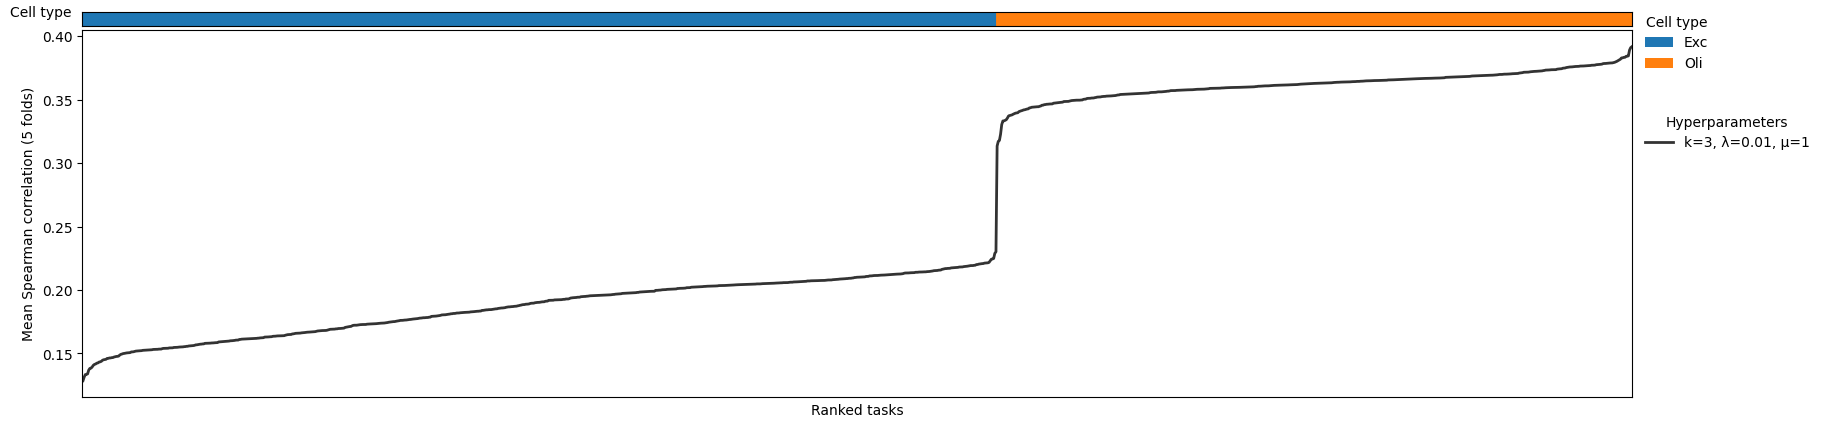

In [12]:
# Training performance line plot
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch

# -------------------------------
# 1. Prepare data
# -------------------------------

DATA_DIR = "./PSIONIC_out"  # load the prediction performance results from last cell

pattern = re.compile(
    r"k(?P<k>\d+)_L(?P<lambda>[0-9.e-]+)_M(?P<mu>[0-9.e-]+)_fold(?P<fold>\d+)"
)

records = []

for fname in os.listdir(DATA_DIR):
    if not fname.startswith("20260726_example_run"):
        continue

    match = pattern.search(fname)
    if match is None:
        continue

    params = match.groupdict()

    df = pd.read_csv(
        os.path.join(DATA_DIR, fname),
        sep=","
    )

    df["k"] = int(params["k"])
    df["lambda"] = float(params["lambda"])
    df["mu"] = float(params["mu"])
    df["fold"] = int(params["fold"])

    records.append(df)

all_df = pd.concat(records, ignore_index=True)


# Compute mean correlation across folds
mean_df = (
    all_df
    .groupby(["k", "lambda", "mu", "task_name"], as_index=False)
    .agg(mean_corr=("correlation", "mean"))
)

# Rank tasks once using the overall mean across all hyperparameters
task_order = (
    mean_df
    .groupby("task_name")["mean_corr"]
    .mean()
    .sort_values()
    .index
)

task_rank = {task: i for i, task in enumerate(task_order)}
mean_df["task_rank"] = mean_df["task_name"].map(task_rank)

# Extract cell type from task_name
mean_df["celltype"] = mean_df["task_name"].str.split("_").str[1]

# Unique cell types
celltypes = mean_df["celltype"].unique()

# Map cell types to colors
cmap = plt.get_cmap("tab10")
celltype_to_color = {ct: cmap(i % cmap.N) for i, ct in enumerate(celltypes)}

# Numeric encoding for heatmap
celltype_to_int = {ct: i for i, ct in enumerate(celltypes)}
mean_df["celltype_int"] = mean_df["celltype"].map(celltype_to_int)

# Reference row for task order (they all share task_rank)
ref_sub = (
    mean_df.sort_values("task_rank")
    .drop_duplicates("task_rank")[["task_name", "task_rank", "celltype_int"]]
)

heatmap_data = ref_sub["celltype_int"].values.reshape(1, -1) #.reshape(1, -1) → reshapes it into a 2D array with 1 row and N columns:

# -------------------------------
# 2. Create figure with gridspec
# -------------------------------
fig = plt.figure(figsize=(20, 5))
gs = fig.add_gridspec(
    2, 1,                         # only 1 column now
    height_ratios=[0.15, 4],
    hspace=0.02
)

ax_heat = fig.add_subplot(gs[0])
ax_line = fig.add_subplot(gs[1], sharex=ax_heat)

# -------------------------------
# 3. Plot heatmap
# -------------------------------
ax_heat.imshow(
    heatmap_data,
    aspect="auto",
    cmap=mcolors.ListedColormap([celltype_to_color[ct] for ct in celltypes])
)
ax_heat.set_yticks([])
ax_heat.set_xticks([])
ax_heat.set_ylabel("Cell type", rotation=0, labelpad=30)

# -------------------------------
# 4. Plot line plot
# -------------------------------

# Group data to find out how many unique lines you have
grouped = mean_df.groupby(["k", "lambda", "mu"])
num_groups = len(grouped)

# Create a colormap  
colors = plt.cm.nipy_spectral(np.linspace(0, 1, num_groups))

for i, ((k, lam, mu), sub) in enumerate(grouped):
    sub = sub.sort_values("task_rank")
    label = f"k={k}, λ={lam:g}, μ={mu:g}"
    
    ax_line.plot(
        sub["task_rank"],
        sub["mean_corr"],
        label=label,
        color=colors[i], 
        linewidth=2,
        alpha=0.8        
    )

ax_line.set_xlabel("Ranked tasks")
ax_line.set_ylabel("Mean Spearman correlation (5 folds)")

# -------------------------------
# 5. Legends on the right
# -------------------------------
# Legends outside
line_handles, line_labels = ax_line.get_legend_handles_labels()
celltype_handles = [Patch(facecolor=celltype_to_color[ct], label=ct) for ct in celltypes]

fig.legend(handles=line_handles, labels=line_labels, title="Hyperparameters",
           bbox_to_anchor=(0.90, 0.7), loc='upper left', frameon=False)
fig.legend(handles=celltype_handles, title="Cell type",
           bbox_to_anchor=(0.90, 0.9), loc='upper left', frameon=False)

plt.show()   

### Interpreting the line plot

- **x-axis:** prediction tasks (i.e., each cell-type- and sample-specific gene expression pseudobulk profile)
- **y-axis:** mean Spearman's correlation across 5 folds for each task

Tasks are ranked by mean correlation, from low to high. This line represents the performance for a **single hyperparameter setting**.

In your own analysis, you can train the model under multiple hyperparameter settings and use this plot to visualize and compare their performance. This helps you identify the best-performing setting, which you can then use to train the final model on the full dataset (as demonstrated in **tutorial part 2**).

In [13]:
import session_info
session_info.show()